<a href="https://colab.research.google.com/github/AhmadSyahreza/Data-Analyst/blob/main/%5BSandbox%5D_Wrangler_Project_Used_Car.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Used Car Price Analysis**


# 0.&nbsp;Import Libraries

In [47]:
# Data Analysis
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Supaya semua kolom & baris tampil (tidak dipotong "...")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

## 0.1 Import Dataset

In [48]:
df = pd.read_csv('used_cars.csv')  # Membaca dataset dari file CSV

In [49]:
df.shape

(1310, 9)

In [50]:
df.head()

,listing_id,brand,body_type,year,fuel,transmission,engine_cc,mileage_km,price_juta
0,101238,Suzuki,SUV,2022.0,P,MT,1000,40151.0,113.6
1,101073,Mazda,Pickup,2023.0,D,MT,1000,25645.0,201.6
2,100454,Lexus,MPV,2023.0,D,MT,1500,11637.0,659.6
3,100363,Lexus,SUV,2018.0,P,MT,1500,135280.0,244.4
4,101018,Kia,Pickup,2015.0,D,AT,1500,93530.0,58.6


In [51]:
df.tail()

,listing_id,brand,body_type,year,fuel,transmission,engine_cc,mileage_km,price_juta
1305,100211,Volvo,MPV,2017.0,D,AT,1000,82877.0,233.3
1306,100502,Suzuki,Sedan,2023.0,D,MT,1800,17878.0,128.9
1307,100537,Toyota,Hatchback,2020.0,D,CVT,1500,105051.0,89.3
1308,101220,Daihatsu,MPV,2014.0,D,MT,2400,83043.0,36.7
1309,100175,Nissan,SUV,2020.0,P,MT,2000,32346.0,128.6


### Kamus kolom (data dictionary)

| Kolom | Arti |
|---|---|
| `listing_id` | ID unik iklan |
| `brand` | Merek mobil (teks bebas, nanti kita *group*) |
| `body_type` | Tipe bodi (MPV, SUV, Sedan, dst.) |
| `year` | Tahun produksi |
| `fuel` | **Kode** jenis bahan bakar (perlu di-*decode*) |
| `transmission` | **Kode** jenis transmisi (perlu di-*decode*) |
| `engine_cc` | Kapasitas mesin (cc) |
| `mileage_km` | Jarak tempuh (km) |
| `price_juta` | Harga jual (juta Rupiah) |

In [52]:
# 'fuel' berisi KODE. Cek nilai unik-nya dulu.
display(df['fuel'].nunique())      # Number of unique
display(df['fuel'].unique())

5

array(['P', 'D', 'L', 'E', 'H'], dtype=object)

Arti kode `fuel`:
*   `P`: Petrol (Bensin)
*   `D`: Diesel
*   `H`: Hybrid
*   `E`: Electric (Listrik)
*   `L`: LPG (Gas)

In [53]:
# 'transmission' juga berisi KODE.
display(df['transmission'].nunique())
display(df['transmission'].unique())

4

array(['MT', 'AT', 'DCT', 'CVT', nan], dtype=object)

Arti kode `transmission`:
*   `MT`: Manual Transmission
*   `AT`: Automatic Transmission
*   `CVT`: Continuously Variable Transmission
*   `DCT`: Dual-Clutch Transmission

**Catatan:** ada `nan` di daftar unik `transmission` → ada *missing values*
yang akan kita tangani di bagian EDA.

# 1.&nbsp;Exploratory Data Analysis (EDA)

## 1.1 Check Null Values

In [54]:
df.isnull().head()

,listing_id,brand,body_type,year,fuel,transmission,engine_cc,mileage_km,price_juta
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False


In [55]:
df.isnull().sum()

,0
listing_id,0
brand,0
body_type,0
year,17
fuel,0
transmission,22
engine_cc,0
mileage_km,18
price_juta,0


In [56]:
missing_values = df.isnull().sum()

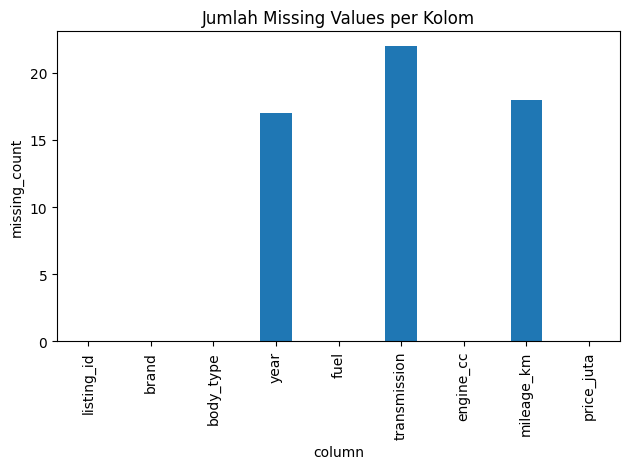

In [92]:
missing_values_df = pd.DataFrame({
    'coloumn' : missing_values.index,
    'missing_count' : missing_values.values
})

# Visualisasikan kolom yang punya missing values
missing_values_df.set_index('column')['missing_count'].plot(kind='bar')
plt.title('Jumlah Missing Values per Kolom')
plt.ylabel('missing_count')
plt.tight_layout();

In [58]:
df.info()  # Cek tipe data (dtype) & jumlah non-null tiap kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1310 entries, 0 to 1309
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   listing_id    1310 non-null   int64  
 1   brand         1310 non-null   object 
 2   body_type     1310 non-null   object 
 3   year          1293 non-null   float64
 4   fuel          1310 non-null   object 
 5   transmission  1288 non-null   object 
 6   engine_cc     1310 non-null   int64  
 7   mileage_km    1292 non-null   float64
 8   price_juta    1310 non-null   float64
dtypes: float64(3), int64(2), object(4)
memory usage: 92.2+ KB


## 1.2 Check Duplicate Data

### 1.2.1 Copy Data (kenapa perlu `.copy()`?)

Assignment biasa (`dm1 = dm`) **tidak** membuat data baru — keduanya menunjuk
objek yang sama, jadi mengubah `dm1` ikut mengubah `dm`. Demo di bawah membuktikannya.

In [59]:
dm = pd.DataFrame(
    data={
        'col1': [1, 2, 3],
        'col2': [4, 5, 6]
    }
)
dm

,col1,col2
0,1,4
1,2,5
2,3,6


In [60]:
dm1 = dm  # BUKAN copy — hanya 'alias' ke objek yang sama

In [61]:
dm1['col1'] = dm1['col1'] + 1  # mengubah dm1 ...

In [62]:
dm  # ... ternyata dm ikut berubah! Inilah kenapa kita butuh .copy()

,col1,col2
0,2,4
1,3,5
2,4,6


In [63]:
# Simpan salinan data asli sebelum transformasi.
df_copy = df.copy()  # Supaya dataset awal tetap aman kalau kita salah transform

In [64]:
df.duplicated()  # True untuk baris yang duplikat dari baris sebelumnya

,0
0,False
1,False
2,False
3,False
4,False
5,False
6,False
7,False
8,False
9,False


In [79]:
df.duplicated().sum()

np.int64(10)

In [65]:
# Tampilkan baris yang terdeteksi duplikat (keep=False -> tandai SEMUA kembarannya)
duplicated_row_mask = df.duplicated(keep=False)
df[duplicated_row_mask].sort_values('listing_id').head(20)

,listing_id,brand,body_type,year,fuel,transmission,engine_cc,mileage_km,price_juta
721,100331,Audi,Sedan,2015.0,P,AT,1500,121002.0,142.8
1183,100331,Audi,Sedan,2015.0,P,AT,1500,121002.0,142.8
581,100435,Audi,Hatchback,2012.0,P,MT,2000,213515.0,60.1
272,100435,Audi,Hatchback,2012.0,P,MT,2000,213515.0,60.1
293,100462,Hyundai,SUV,2014.0,D,DCT,1500,132325.0,47.4
204,100462,Hyundai,SUV,2014.0,D,DCT,1500,132325.0,47.4
1049,100711,Hyundai,Hatchback,NaN,E,MT,1500,82793.0,57.7
758,100711,Hyundai,Hatchback,NaN,E,MT,1500,82793.0,57.7
820,100789,Honda,Sedan,2019.0,P,MT,1500,51865.0,106.7
273,100789,Honda,Sedan,2019.0,P,MT,1500,51865.0,106.7


### 1.2.2 Delete Duplicates

In [66]:
print(f"Jumlah duplikasi sebelum dihapus: {df_copy.duplicated().sum()}")

df_copy.drop_duplicates(inplace=True)

print(f"Jumlah duplikasi sesudah dihapus: {df_copy.duplicated().sum()}")
print(f"Shape sesudah: {df_copy.shape}")

Jumlah duplikasi sebelum dihapus: 10
Jumlah duplikasi sesudah dihapus: 0
Shape sesudah: (1300, 9)


## 1.3 Check Unique Values in Each Column

### 1.3.1 Check Data Shape

In [67]:
df_copy.shape

(1300, 9)

### 1.3.2 Check Data Type

In [68]:
df_copy.dtypes

,0
listing_id,int64
brand,object
body_type,object
year,float64
fuel,object
transmission,object
engine_cc,int64
mileage_km,float64
price_juta,float64


### 1.3.3 Check Data Stats

In [69]:
df_copy.describe()  # Statistik ringkas untuk kolom numerik

,listing_id,year,engine_cc,mileage_km,price_juta
count,1300.000000,1285.000000,1300.000000,1282.000000,1300.000000
mean,100649.500000,2017.414008,1693.230769,97065.074103,140.647000
std,375.421985,3.425640,475.950029,66961.469214,132.868438
min,100000.000000,2012.000000,1000.000000,500.000000,15.600000
25%,100324.750000,2015.000000,1500.000000,42527.250000,50.475000
50%,100649.500000,2017.000000,1500.000000,86160.000000,94.750000
75%,100974.250000,2020.000000,2000.000000,137520.250000,171.925000
max,101299.000000,2023.000000,3000.000000,389798.000000,728.000000


### 1.3.4 Check Unique Values

In [70]:
# Kolom numerik kontinu / ID tidak berguna dilihat unik-nya, jadi dikecualikan.
excepted_columns = [
    'listing_id', 'engine_cc', 'mileage_km', 'price_juta'
]

for col in df_copy.columns:
    if col not in excepted_columns:
        print(f"{col}: {df_copy[col].nunique()} unique")
        print(f"{df_copy[col].unique()}")
        print("")

brand: 15 unique
['Suzuki' 'Mazda' 'Lexus' 'Kia' 'Honda' 'Audi' 'BMW' 'Mercedes-Benz'
 'Toyota' 'Nissan' 'Daihatsu' 'Mitsubishi' 'Wuling' 'Volvo' 'Hyundai']

body_type: 5 unique
['SUV' 'Pickup' 'MPV' 'Hatchback' 'Sedan']

year: 12 unique
[2022. 2023. 2018. 2015. 2019.   nan 2014. 2021. 2017. 2016. 2013. 2020.
 2012.]

fuel: 5 unique
['P' 'D' 'L' 'E' 'H']

transmission: 4 unique
['MT' 'AT' 'DCT' 'CVT' nan]



### 1.3.5 Check Columns

In [71]:
df_copy.columns

Index(['listing_id', 'brand', 'body_type', 'year', 'fuel', 'transmission',
       'engine_cc', 'mileage_km', 'price_juta'],
      dtype='object')

## 1.4 Rename Value for Better Understanding

Kolom `fuel` & `transmission` masih berupa **kode**. Buat *dictionary* pemetaan
agar lebih mudah dibaca manusia.

In [72]:
dict_fuel = {
    'P': 'Petrol',
    'D': 'Diesel',
    'H': 'Hybrid',
    'E': 'Electric',
    'L': 'LPG',
}

dict_transmission = {
    'MT':  'Manual',
    'AT':  'Automatic',
    'CVT': 'CVT',
    'DCT': 'Dual-Clutch',
}

### 1.4.1 Replace Values

Pendekatan **pertama**: `.replace()` menimpa (overwrite) kode menjadi label panjang
**di kolom yang sama**.

In [73]:
df_1 = df_copy.copy()

In [80]:
df_1['fuel'] = df_1['fuel'].replace(dict_fuel)
df_1['transmission'] = df_1['transmission'].replace(dict_transmission)

In [74]:
df_1.head(10)

,listing_id,brand,body_type,year,fuel,transmission,engine_cc,mileage_km,price_juta
0,101238,Suzuki,SUV,2022.0,P,MT,1000,40151.0,113.6
1,101073,Mazda,Pickup,2023.0,D,MT,1000,25645.0,201.6
2,100454,Lexus,MPV,2023.0,D,MT,1500,11637.0,659.6
3,100363,Lexus,SUV,2018.0,P,MT,1500,135280.0,244.4
4,101018,Kia,Pickup,2015.0,D,AT,1500,93530.0,58.6
5,100503,Honda,Pickup,2019.0,P,MT,1800,96124.0,83.4
6,101236,Audi,SUV,2019.0,L,DCT,1800,33517.0,320.6
7,100887,BMW,Hatchback,2022.0,D,AT,1800,26827.0,397.6
8,100034,Honda,Sedan,NaN,D,DCT,2500,81941.0,81.4
9,100407,Mazda,Sedan,2018.0,E,MT,1200,70423.0,107.1


### 1.4.2 Map Values

Pendekatan **kedua**: `.map()` untuk membuat **kolom deskripsi baru** di sebelah
kolom aslinya (kode asli tetap dipertahankan).

In [75]:
df_2 = df_copy.copy()

In [82]:
df_2.insert(
    loc = list(df_2.columns).index('fuel')+1,
    column = 'fuel_desc',
    value = df_2['fuel'].map(dict_fuel)
)

In [83]:
df_2.insert(
    loc = list(df_2.columns).index('transmission')+1,
    column = 'transmission_desc',
    value = df_2['transmission'].map(dict_transmission)
)

> **Perbedaan `replace` vs `map`:** `.map()` mengubah nilai yang **tidak ada di
> dictionary** menjadi `NaN`, sedangkan `.replace()` membiarkannya apa adanya.

## 1.5 Group the Brand

Kolom `brand` bisa dikelompokkan ke **segmen pasar** (broader category) untuk
menyederhanakan analisis.

### Check Brand

In [76]:
df_1['brand'].unique()

array(['Suzuki', 'Mazda', 'Lexus', 'Kia', 'Honda', 'Audi', 'BMW',
       'Mercedes-Benz', 'Toyota', 'Nissan', 'Daihatsu', 'Mitsubishi',
       'Wuling', 'Volvo', 'Hyundai'], dtype=object)

### Grouping Function

In [93]:
segment_mapping = {
    "Mass Market": [
        "Toyota",
        "Honda",
        "Suzuki",
        "Daihatsu",
        "Mitsubishi",
        "Nissan",
        "Mazda",
    ],
    "Value Brand": [
        "Hyundai",
        "Kia",
        "Wuling",
    ],
    "Premium": [
        "BMW",
        "Mercedes-Benz",
        "Audi",
        "Lexus",
        "Volvo",
    ],
}


def assign_segment(brand, mapper):
   for segment, brands in mapper.items():
    if brand in brands :
      return segment
   return "other"

In [94]:
if 'segment' in df_1.columns :
  df_1.drop(columns=['segment'], inplace=True)

df_1.insert(
    loc= list(df_1.columns).index('brand')+1,
    column = 'segment',
    value = df_1['brand'].apply(lambda x: assign_segment(x, segment_mapping))
)

In [97]:
df_1.head()

,listing_id,brand,segment,body_type,year,fuel,transmission,engine_cc,mileage_km,price_juta
0,101238,Suzuki,Mass Market,SUV,2022.0,Petrol,Manual,1000,40151.0,113.6
1,101073,Mazda,Mass Market,Pickup,2023.0,Diesel,Manual,1000,25645.0,201.6
2,100454,Lexus,Premium,MPV,2023.0,Diesel,Manual,1500,11637.0,659.6
3,100363,Lexus,Premium,SUV,2018.0,Petrol,Manual,1500,135280.0,244.4
4,101018,Kia,Value Brand,Pickup,2015.0,Diesel,Automatic,1500,93530.0,58.6


In [95]:
df_1[df_1['segment'] == 'Other']['brand'].unique()

array([], dtype=object)

## 1.6 Adjust Price to Present Value (kolom turunan)

Harga dari tahun berbeda tidak langsung setara nilainya karena **inflasi**.
Kita buat kolom turunan `adjusted_price_juta` yang menyetarakan harga ke tahun
**2023**.

In [96]:
# Asumsi tingkat inflasi tahunan Indonesia (untuk latihan saja)
inflation_rates = {
    2012: 0.043, 2013: 0.064, 2014: 0.064, 2015: 0.036,
    2016: 0.030, 2017: 0.038, 2018: 0.032, 2019: 0.028,
    2020: 0.017, 2021: 0.016, 2022: 0.041,
}

def adjust_price(row):
    year = row['year']

    # Kalau tahun kosong (NaN), kembalikan harga asli tanpa penyesuaian
    if pd.isna(year):
        return row['price_juta']

    year = int(year)
    value = row['price_juta']

    # Kalau sudah tahun 2023, tidak perlu disesuaikan
    if year >= 2023:
        return value

    # inflasi dari tahun produksi sampai 2022
    for y in range(year, 2023):
        rate = inflation_rates.get(y, 0.0)
        value = value * (1 + rate)
    return round(value, 2)

In [99]:
# Membuat kolom adjusted_price_juta menggunakan fungsi adjust_price
df_1['adjusted_price_juta'] = df_1.apply(adjust_price, axis=1)

# Menampilkan data yang diminta
df_1[['brand','year','price_juta','adjusted_price_juta']].head()

,brand,year,price_juta,adjusted_price_juta
0,Suzuki,2022.0,113.6,118.26
1,Mazda,2023.0,201.6,201.60
2,Lexus,2023.0,659.6,659.60
3,Lexus,2018.0,244.4,278.89
4,Kia,2015.0,58.6,74.07


In [100]:
df_1[['brand','year','price_juta','adjusted_price_juta']].head()

,brand,year,price_juta,adjusted_price_juta
0,Suzuki,2022.0,113.6,118.26
1,Mazda,2023.0,201.6,201.60
2,Lexus,2023.0,659.6,659.60
3,Lexus,2018.0,244.4,278.89
4,Kia,2015.0,58.6,74.07


 **Kenapa `adjusted >= price`?** Karena kita membawa harga lama ke nilai tahun 2023
  (mengalikan `1 + inflasi`), jadi harga yang disesuaikan selalu **≥** harga asli.
 Untuk mobil tahun 2023 keduanya sama.

---
# LATIHAN (SOAL)

Gunakan `df_1` (data yang sudah dibersihkan & ditransformasi) untuk menjawab.

## SOAL No.1
Tampilkan **median** `adjusted_price_juta` untuk **setiap `segment`**,
urutkan dari terbesar ke terkecil.

In [105]:
df_1.groupby('segment')['adjusted_price_juta'].median().reset_index().sort_values(by='adjusted_price_juta', ascending=False)

#disini pakai logika dari sql yaitu groupby karena kita mau berdasarkan segment
#untuk menampilkan apa yang kita mau itu pakai .median()
#pakai .sort_values utk mengurutkan datanya

,segment,adjusted_price_juta
1,Premium,256.70
0,Mass Market,77.20
2,Value Brand,75.61


## SOAL No.2
Tampilkan **jumlah record** untuk setiap `brand`, urutkan **descending**.

In [107]:
df_1['brand'].value_counts().reset_index()

#Ini juga logikanya ialah kita menghitung jumlah dari nama brandnya ada berapa

,brand,count
0,Honda,102
1,Mercedes-Benz,101
2,Suzuki,95
3,BMW,94
4,Mazda,93
5,Mitsubishi,90
6,Volvo,90
7,Hyundai,89
8,Audi,84
9,Kia,82


## SOAL No.3
Tampilkan **rata-rata harga** (`price_juta`) untuk setiap `fuel`.
Apakah rata-rata di sini bisa menyesatkan? Kenapa?

In [108]:
df_1.groupby('fuel')['price_juta'].mean().reset_index().sort_values(by='price_juta', ascending=False)

#ini kelompokan dlu pakai groupby
#ambil mean pakai rumus .mean(), kemudian urutkan menggunakan sort_values berdasarkan 'price_juta'

,fuel,price_juta
3,LPG,162.494286
2,Hybrid,147.541176
0,Diesel,147.245143
1,Electric,138.325000
4,Petrol,134.717278


## SOAL No.4
Adakah hubungan antara `mileage_km` dan `price_juta`? Hitung **korelasi**-nya
dan tampilkan **scatter plot**.

In [112]:
korelasi = df_1['mileage_km'].corr(df_1['price_juta'])
print(f"Korelasi antara mileage_km dan price_juta: " + str(korelasi))

Korelasi antara mileage_km dan price_juta: -0.5027495367022554


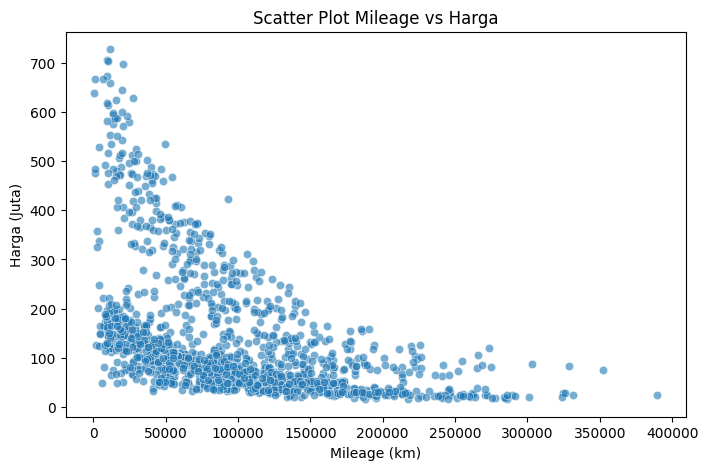

In [114]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_1, x='mileage_km', y='price_juta', alpha=0.6)
plt.title('Scatter Plot Mileage vs Harga')
plt.xlabel('Mileage (km)')
plt.ylabel('Harga (Juta)')
plt.show()

#ini cara ngeplot pakai seaborn sama matplotlib

## SOAL No.5
Buat tabel: untuk tiap `segment`, tampilkan **jumlah mobil**, **harga rata-rata**,
dan **rata-rata kilometer**. Segmen mana yang paling mahal rata-rata?

In [115]:
df_5 = df_1.groupby('segment').agg(
    jumlah_mobil=('segment', 'count'),
    harga_rata_rata=('price_juta', 'mean'),
    rata_rata_kilometer=('mileage_km', 'mean')
).reset_index().sort_values(by='harga_rata_rata', ascending=False)

display(df_5)

,segment,jumlah_mobil,harga_rata_rata,rata_rata_kilometer
1,Premium,444,262.222973,95019.093607
0,Mass Market,604,78.168212,98877.546218
2,Value Brand,252,76.192460,96333.020080
